# 01 – Data Understanding
**Owner:** Tony  
**Goal:** Load the raw Kaggle NBA Games data, describe every variable and the target, and check data quality.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")

FIGURES.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Load raw data
Load `public.dim_games.csv` from the `data/raw/` directory. This dataset contains historical NBA game records, including game dates, team information, final scores, and team performance statistics.

In [2]:
games = pd.read_csv(RAW / "public.dim_games.csv", low_memory= False)
print("Dataset shape:", games.shape)
display(games.head())

Dataset shape: (74569, 101)


,game_id,game_date,season,season_type,home_team_id,home_team_abbr,home_team_name,home_pts,home_fg_pct,home_fg3_pct,...,arena_state,duration,api_season,api_status,saved_at,imported_at,br_crawled_id,nba_api_id,br_no_boxscore,pbp_no_data
0,198211270KCK,1982-11-27,1983,Regular Season,1610612758,KCK,Kansas City Kings,105,0.425,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28200163.0,f,f
1,194611230WAS,1946-11-23,1947,Regular Season,1610612764,WAS,Washington Capitols,74,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24600045.0,f,f
2,198211300GOS,1982-11-30,1983,Regular Season,1610612744,GOS,Golden State Warriors,110,0.512,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28200181.0,f,f
3,198212120POR,1982-12-12,1983,Regular Season,1610612757,POR,Portland Trail Blazers,99,0.400,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28200249.0,f,f
4,198212250UTH,1982-12-25,1983,Regular Season,1610612762,UTH,Utah Jazz,101,0.406,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28200311.0,f,f


## Variables and target
Target: `HOME_TEAM_WINS` (1 = home team won, 0 = home team lost).

Variable Explanation:

| Variable | Type | Description |
|---|---|---|
| `game_id` | Identifier | Unique game ID |
| `game_date` | Date (stored as text) | Date of the game |
| `season` | Integer | NBA season-ending year |
| `season_type` | Categorical | Regular season, playoffs, etc. |
| `home_team_name` | Categorical | Home team |
| `away_team_name` | Categorical | Away team |
| `home_pts`, `away_pts` | Numerical | Final points scored |
| `home_fg_pct`, `away_fg_pct` | Numerical | Field-goal percentage, stored as 0–1 |
| `home_reb`, `away_reb` | Numerical | Total rebounds |
| `home_ast`, `away_ast` | Numerical | Total assists |
| `home_tov`, `away_tov` | Numerical | Turnovers |
| `HOME_TEAM_WINS` | Binary | 1 = home win, 0 = home loss |


In [3]:
games["HOME_TEAM_WINS"] = (games["home_pts"] > games["away_pts"]).astype(int)

games.info()
display(games.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74569 entries, 0 to 74568
Columns: 102 entries, game_id to HOME_TEAM_WINS
dtypes: float64(71), int64(4), object(27)
memory usage: 58.0+ MB


,count,mean,std,min,25%,50%,75%,max
season,74569.0,1.995879e+03,2.017352e+01,1947.00,1.982000e+03,1.998000e+03,2.013000e+03,2.026000e+03
home_pts,74569.0,1.053827e+02,1.479861e+01,18.00,9.600000e+01,1.050000e+02,1.150000e+02,1.920000e+02
home_fg_pct,53052.0,4.679769e-01,5.921070e-02,0.14,4.270000e-01,4.670000e-01,5.070000e-01,6.970000e-01
home_fg3_pct,37100.0,3.425113e-01,1.626222e-01,0.00,2.500000e-01,3.330000e-01,4.380000e-01,1.000000e+00
home_ft_pct,65534.0,6.099966e-01,3.075228e-01,0.00,6.090000e-01,7.270000e-01,8.000000e-01,4.167000e+00
...,...,...,...,...,...,...,...,...
away_fga3,12378.0,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
api_season,1225.0,2.024000e+03,0.000000e+00,2024.00,2.024000e+03,2.024000e+03,2.024000e+03,2.024000e+03
api_status,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nba_api_id,74187.0,2.615291e+07,6.518118e+06,10500001.00,2.140021e+07,2.590007e+07,2.900002e+07,5.250021e+07


In [4]:
print("Missing home scores:",
      games["home_pts"].isna().sum())

print("Missing away scores:",
      games["away_pts"].isna().sum())

print("Negative home scores:",
      (games["home_pts"] < 0).sum())

print("Negative away scores:",
      (games["away_pts"] < 0).sum())

print("Tied final scores:",
      (games["home_pts"] == games["away_pts"]).sum())

Missing home scores: 0
Missing away scores: 0
Negative home scores: 0
Negative away scores: 0
Tied final scores: 0


## Data quality: missing values, duplicates, unusual values

In [5]:
missing = games.isna().sum().sort_values(ascending=False)
print("Missing values:")
print(missing[missing > 0])
print("Duplicate rows:", games.duplicated().sum())
print("Duplicate game IDs:", games["game_id"].duplicated().sum())

Missing values:
series_summary    74569
api_status        74569
location          74565
home_ot           74509
away_ot           74509
                  ...  
away_wl             531
nba_api_id          382
game_status          90
away_team_name        4
home_team_name        4
Length: 89, dtype: int64
Duplicate rows: 0
Duplicate game IDs: 0


In [6]:
# Check missing values by season (2000–2025)

study_games = games[
    (games["season"].between(2000, 2025)) &
    (games["season_type"] == "Regular Season")
].copy()

columns = [
    "home_reb", "away_reb",
    "home_ast", "away_ast",
    "home_fg3_pct", "away_fg3_pct",
    "home_tov", "away_tov"
]

missing_by_season = (
    study_games.groupby("season")[columns]
    .apply(lambda x: x.isna().mean() * 100)
)

display(missing_by_season.round(1))

,home_reb,away_reb,home_ast,away_ast,home_fg3_pct,away_fg3_pct,home_tov,away_tov
season,,,,,,,,
2000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2002,1.2,1.2,1.2,1.2,1.2,1.2,1.2,1.2
2003,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2004,0.3,0.3,0.3,0.3,0.3,0.3,0.3,0.3
2005,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2007,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2008,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


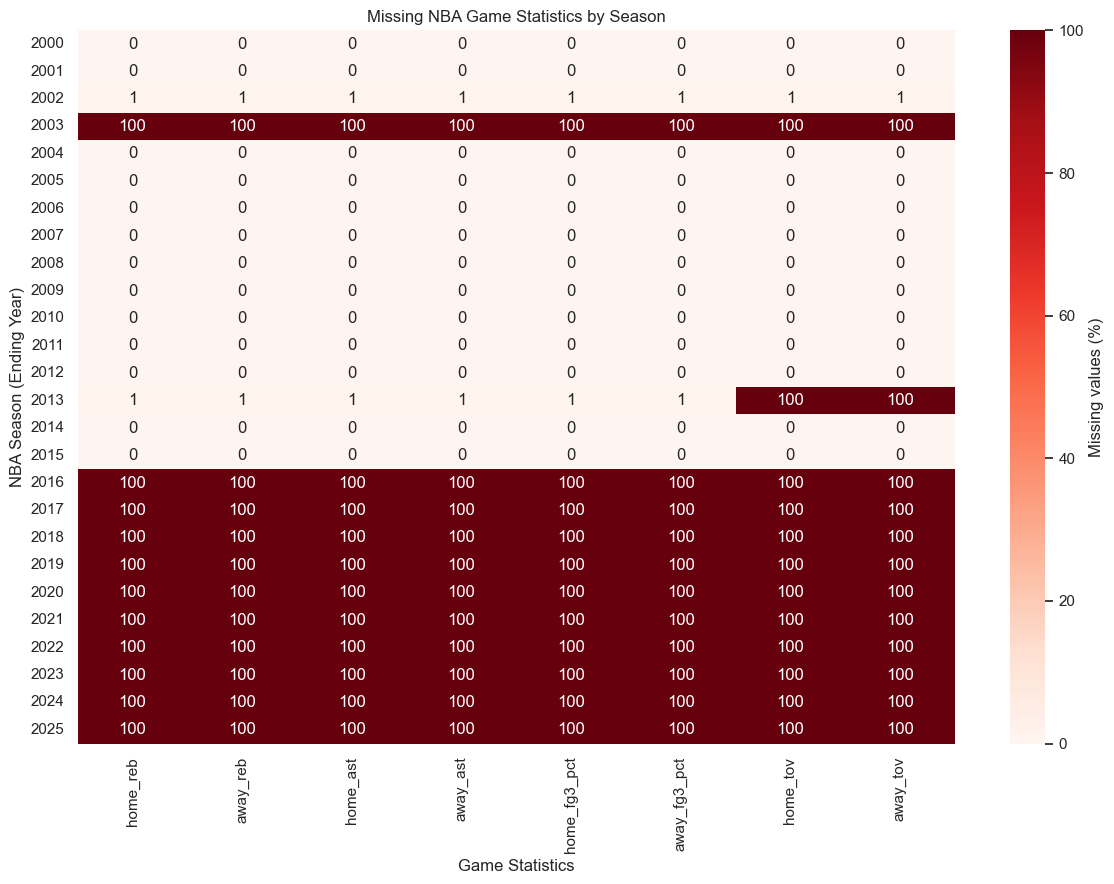

In [7]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    missing_by_season,
    annot=True,
    fmt=".0f",
    cmap="Reds",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Missing values (%)"}
)

plt.title("Missing NBA Game Statistics by Season")
plt.xlabel("Game Statistics")
plt.ylabel("NBA Season (Ending Year)")

plt.tight_layout()
plt.show()

Study period overview: Temporarily shrink down the seasons to examine

In [8]:
print("Study period: 1999-00 to 2024-25")
print("Number of seasons:", study_games["season"].nunique())
print("Number of regular-season games:", len(study_games))

print("\nGames per season:")
display(
    study_games.groupby("season")
    .size()
    .rename("number_of_games")
    .to_frame()
)

Study period: 1999-00 to 2024-25
Number of seasons: 26
Number of regular-season games: 31230

Games per season:


,number_of_games
season,
2000,1189
2001,1189
2002,1203
2003,1189
2004,1192
2005,1230
2006,1230
2007,1230
2008,1230


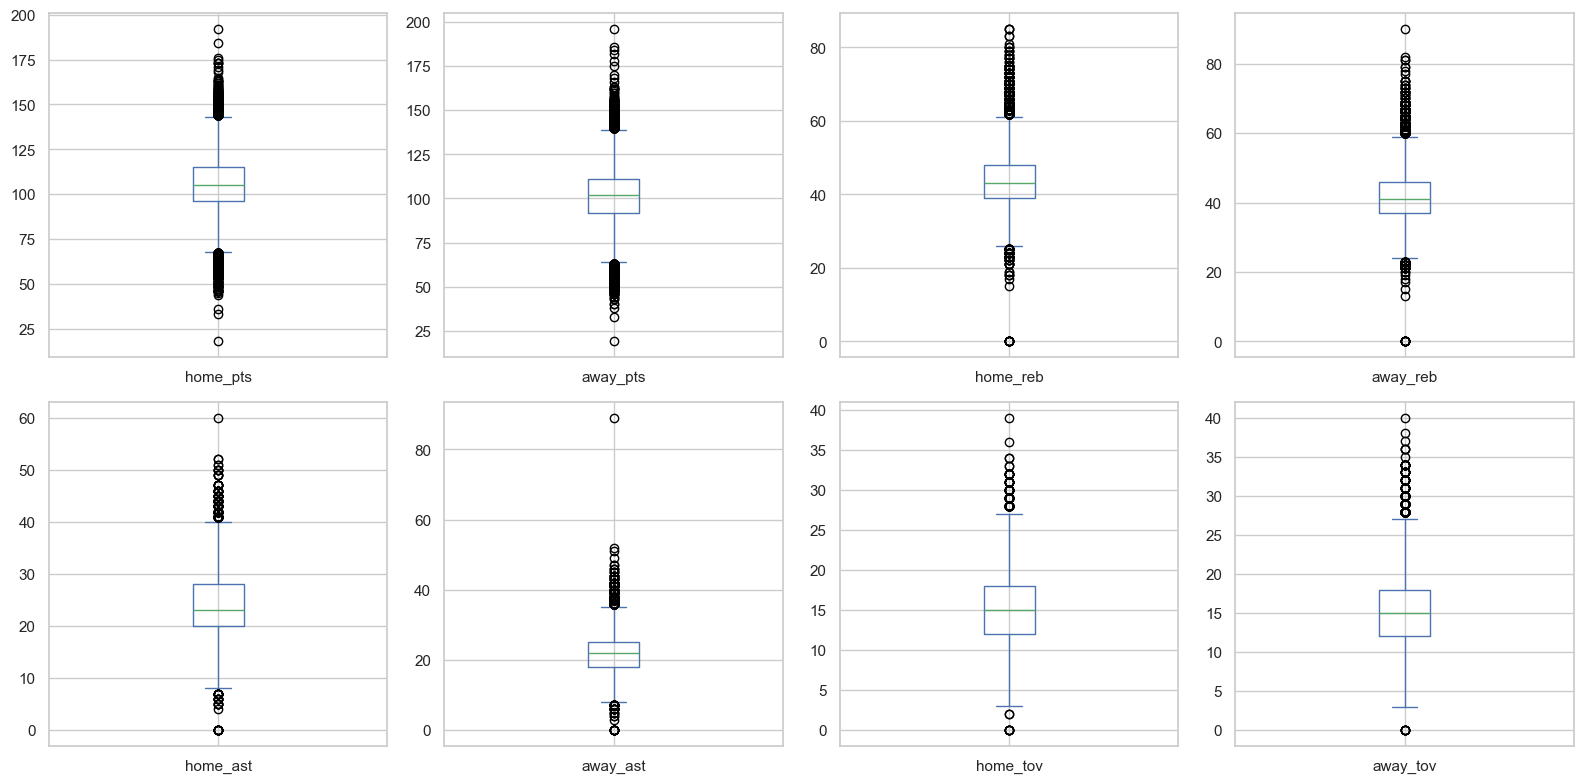

In [9]:
num_cols = [
    "home_pts",
    "away_pts",
    "home_reb",
    "away_reb",
    "home_ast",
    "away_ast",
    "home_tov",
    "away_tov"
]

games[num_cols].plot(kind="box", subplots=True, layout=(2, 4), figsize=(16, 8), sharey=False)
plt.tight_layout()
plt.show()

## Target balance

In [10]:
print(games["HOME_TEAM_WINS"].value_counts())

print(
    games["HOME_TEAM_WINS"].value_counts(
        normalize=True
    ) * 100
)

HOME_TEAM_WINS
1    45338
0    29231
Name: count, dtype: int64
HOME_TEAM_WINS
1    60.800064
0    39.199936
Name: proportion, dtype: float64


## Data Understanding Summary

The raw NBA dataset contains 74,569 game records and 101 original columns. The data includes team information, game dates, final scores, shooting statistics, rebounds, assists, turnovers, and additional game metadata.

The dataset contains no duplicate rows or duplicate game IDs. However, several variables contain missing values. Miss data is especially significant in some team performance statistics during recent seasons, which may affect the project's selected features.

Box plots reveal potential outliers in points, rebounds, assists, and turnovers. These values require further investigation because unusual basketball performances are not necessarily data errors.

The target variable, HOME_TEAM_WINS, is derived from the final home and away scores. The raw-data target distribution shows approximately 60.8% home wins and 39.2% home losses. This distribution covers the full historical dataset rather than only the selected study period.

The team plans to analyze regular-season games from the 1999–2000 through 2024–25 seasons. Filtering, cleaning, and treatment of missing values will be handled in Notebook 2.

### Additional Data Quality Findings

**Study Period**

The project focuses on 26 NBA regular seasons, from 1999–2000 through 2024–2025. The original dataset contains 74,569 historical NBA game records, including games outside the selected study period.

**Missing Values**

The missing-value analysis identified substantial gaps in several important game statistics. Rebounds, assists, three-point shooting percentages, and turnovers are completely missing for the 2016–2025 seasons.

The 2002–2003 season also has 100% missing values for these statistics, while the 2012–2013 season has 100% missing turnovers.

These findings suggest that missing values are concentrated in particular seasons rather than randomly distributed across all games.

**Duplicates and Outliers**

No duplicate rows or duplicate game IDs were found in the raw dataset.

Box plots identified potential outliers in points, rebounds, assists, and turnovers. These observations may represent unusual but legitimate basketball performances and should be verified before any removal.

**Implications for Preprocessing**

The missing statistics present a significant challenge for building prediction models across the full 26-season period. Before preprocessing is finalized, the team should investigate whether the missing information can be obtained from another data source.

The original dataset will remain unchanged in Notebook 1. Filtering, cleaning, feature engineering, and exporting the processed dataset will be performed in Notebook 2.

## Notes for preprocessing

- The dataset contains NBA game-level records, including home and away teams, final scores, and team performance statistics.
- The target variable, `HOME_TEAM_WINS`, will be created using home and away final scores.
- Only regular-season games from the selected study period will be used for the project.
- Duplicate game IDs and records with invalid or missing scores must be checked.
- Several performance statistics contain missing values, so missingness should be investigated by season before selecting a treatment.
- Potential outliers in points, rebounds, assists, and turnovers will be examined before removing any records.
- The cleaned dataset will be saved separately in `data/processed/` for exploratory analysis and modeling.
